# PPO Policy Evaluation Analysis

This notebook analyzes evaluation results for gold, vanilla, and maxmin PPO policies across different alpha values (0.6 to 1.0).

## Datasets Analyzed
- **Methods**: gold, vanilla, maxmin
- **Alpha values**: 0.6, 0.7, 0.8, 0.9, 1.0
- **Metrics**: positiveness, length, normalized_length


In [15]:
import sys
import os
FILE_DIR = os.path.dirname(os.path.abspath('__file__'))
ROOT = os.path.abspath(os.path.join(FILE_DIR, ".."))
sys.path.insert(0, ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
%matplotlib inline


## Configuration


In [16]:
# Configuration
USER_ID = "mxcui"  # Change to your HuggingFace username
SEED = 42
PROPORTION = 0.2
METHODS = ["gold-vanilla", "gold", "vanilla", "maxmin"]
ALPHAS = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

print(f"Loading evaluation datasets for:")
print(f"  User ID: {USER_ID}")
print(f"  Methods: {METHODS}")
print(f"  Alpha values: {ALPHAS}")
print(f"  Seed: {SEED}")
print(f"  Proportion: {PROPORTION}")


Loading evaluation datasets for:
  User ID: mxcui
  Methods: ['gold-vanilla', 'gold', 'vanilla', 'maxmin']
  Alpha values: [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
  Seed: 42
  Proportion: 0.2


## Groundtruth (Training Dataset) Analysis


In [17]:
def load_groundtruth_dataset(user_id):
    """Load scored training/groundtruth dataset from HuggingFace Hub."""
    dataset_name = f"{user_id}/gpt2-imdb-raw"
    try:
        loaded_dataset = load_dataset(dataset_name)
        if hasattr(loaded_dataset, 'keys') and len(loaded_dataset.keys()) > 0:
            split_name = list(loaded_dataset.keys())[0]
            dataset = loaded_dataset[split_name]
        else:
            dataset = loaded_dataset

        df = dataset.to_pandas()
        return df
    except Exception as e:
        print(f"Failed to load {dataset_name}: {e}")
        return None


def build_groundtruth_long_df(df):
    """Convert response_0/1 style training data to one-row-per-response format."""
    response_indices = []
    for col in df.columns:
        if col.startswith('response_'):
            suffix = col.replace('response_', '')
            if suffix.isdigit():
                response_indices.append(int(suffix))
    response_indices = sorted(set(response_indices))

    if not response_indices:
        for col in df.columns:
            if col.startswith('positiveness_'):
                suffix = col.replace('positiveness_', '')
                if suffix.isdigit():
                    response_indices.append(int(suffix))
        response_indices = sorted(set(response_indices))

    if not response_indices:
        print('No response_i columns found in training dataset.')
        return None

    parts = []
    for i in response_indices:
        response_col = f'response_{i}'
        pos_col = f'positiveness_{i}'
        norm_len_col = f'normalized_length_{i}'
        len_col = f'length_{i}'

        required = [response_col, pos_col, norm_len_col]
        if not all(col in df.columns for col in required):
            continue

        part = pd.DataFrame({
            'prompt': df['prompt'] if 'prompt' in df.columns else None,
            'completion': df[response_col],
            'response_id': i,
            'positiveness': pd.to_numeric(df[pos_col], errors='coerce'),
            'normalized_length': pd.to_numeric(df[norm_len_col], errors='coerce'),
        })

        if len_col in df.columns:
            part['length'] = pd.to_numeric(df[len_col], errors='coerce')
        else:
            part['length'] = part['normalized_length'] * 100.0

        parts.append(part)

    if not parts:
        print('No valid response metric columns found in training dataset.')
        return None

    long_df = pd.concat(parts, ignore_index=True)
    long_df = long_df.dropna(subset=['positiveness', 'normalized_length'])
    long_df['dataset'] = 'groundtruth_train'
    return long_df


train_raw_df = load_groundtruth_dataset(USER_ID)
if train_raw_df is not None and len(train_raw_df) > 0:
    train_long_df = build_groundtruth_long_df(train_raw_df)
    if train_long_df is not None and len(train_long_df) > 0:
        print('Groundtruth/Training Dataset Loaded')
        print('=' * 60)
        print(f'Raw shape: {train_raw_df.shape}')
        print(f'Long-form shape: {train_long_df.shape}')
        print(f'Responses per prompt (detected): {train_long_df["response_id"].nunique()}')
        print(f"Positiveness range: [{train_long_df['positiveness'].min():.4f}, {train_long_df['positiveness'].max():.4f}]")
        print(f"Normalized length range: [{train_long_df['normalized_length'].min():.4f}, {train_long_df['normalized_length'].max():.4f}]")
    else:
        print('Groundtruth/training analysis skipped: failed to build long-form dataframe.')
else:
    print('Groundtruth/training analysis skipped: dataset not available.')


Groundtruth/Training Dataset Loaded
Raw shape: (24895, 9)
Long-form shape: (49790, 7)
Responses per prompt (detected): 2
Positiveness range: [0.0028, 0.9965]
Normalized length range: [0.0300, 1.0000]


Groundtruth Alpha Summary (training dataset)
   alpha  positiveness_mean  normalized_length_mean  minority_score_mean  \
0    0.5               0.62                  0.7798               0.4201   
1    0.6               0.62                  0.7798               0.3801   
2    0.7               0.62                  0.7798               0.3402   
3    0.8               0.62                  0.7798               0.3002   
4    0.9               0.62                  0.7798               0.2602   
5    1.0               0.62                  0.7798               0.2202   

   majority_score_mean  group_gap_mean  
0               0.4201          0.0000  
1               0.4601          0.0800  
2               0.5001          0.1599  
3               0.5401          0.2399  
4               0.5800          0.3198  
5               0.6200          0.3998  


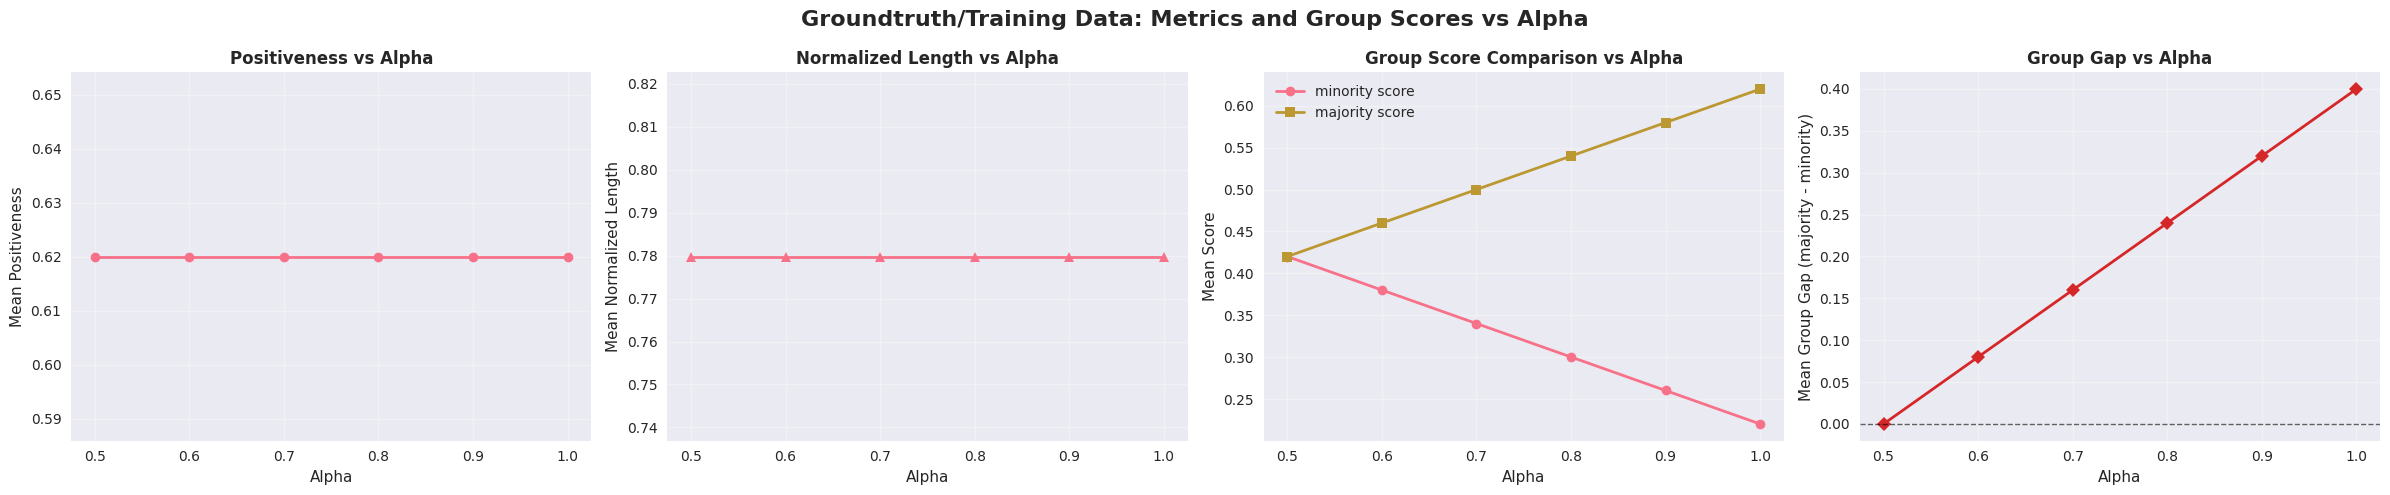

In [18]:
if 'train_long_df' in locals() and train_long_df is not None and len(train_long_df) > 0:
    # Compute alpha-based scores using the same fairness formulas.
    gt_rows = []
    for alpha in ALPHAS:
        minority_score = (1 - train_long_df['normalized_length']) * alpha + (1 - alpha) * train_long_df['positiveness']
        majority_score = (1 - train_long_df['normalized_length']) * (1 - alpha) + alpha * train_long_df['positiveness']

        gt_rows.append({
            'alpha': alpha,
            'positiveness_mean': train_long_df['positiveness'].mean(),
            'normalized_length_mean': train_long_df['normalized_length'].mean(),
            'minority_score_mean': minority_score.mean(),
            'majority_score_mean': majority_score.mean(),
            'group_gap_mean': (majority_score - minority_score).mean(),
        })

    groundtruth_alpha_summary = pd.DataFrame(gt_rows)

    print('Groundtruth Alpha Summary (training dataset)')
    print('=' * 80)
    print(groundtruth_alpha_summary.round(4))

    fig, axes = plt.subplots(1, 4, figsize=(24, 5))
    fig.suptitle('Groundtruth/Training Data: Metrics and Group Scores vs Alpha', fontsize=16, fontweight='bold')

    # 1. Positiveness vs alpha
    ax1 = axes[0]
    ax1.plot(groundtruth_alpha_summary['alpha'], groundtruth_alpha_summary['positiveness_mean'], marker='o', linewidth=2)
    ax1.set_xlabel('Alpha')
    ax1.set_ylabel('Mean Positiveness')
    ax1.set_title('Positiveness vs Alpha', fontweight='bold')
    ax1.grid(True, alpha=0.3)

    # 2. Normalized length vs alpha
    ax2 = axes[1]
    ax2.plot(groundtruth_alpha_summary['alpha'], groundtruth_alpha_summary['normalized_length_mean'], marker='^', linewidth=2)
    ax2.set_xlabel('Alpha')
    ax2.set_ylabel('Mean Normalized Length')
    ax2.set_title('Normalized Length vs Alpha', fontweight='bold')
    ax2.grid(True, alpha=0.3)

    # 3. Group score comparison vs alpha
    ax3 = axes[2]
    ax3.plot(groundtruth_alpha_summary['alpha'], groundtruth_alpha_summary['minority_score_mean'], marker='o', linewidth=2, label='minority score')
    ax3.plot(groundtruth_alpha_summary['alpha'], groundtruth_alpha_summary['majority_score_mean'], marker='s', linewidth=2, label='majority score')
    ax3.set_xlabel('Alpha')
    ax3.set_ylabel('Mean Score')
    ax3.set_title('Group Score Comparison vs Alpha', fontweight='bold')
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    # 4. Group gap vs alpha
    ax4 = axes[3]
    ax4.plot(groundtruth_alpha_summary['alpha'], groundtruth_alpha_summary['group_gap_mean'], marker='D', linewidth=2, color='tab:red')
    ax4.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.6)
    ax4.set_xlabel('Alpha')
    ax4.set_ylabel('Mean Group Gap (majority - minority)')
    ax4.set_title('Group Gap vs Alpha', fontweight='bold')
    ax4.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


## Load Evaluation Datasets


In [19]:
def load_evaluation_dataset(user_id, method, proportion, alpha, seed):
    """Load evaluation dataset from HuggingFace Hub."""
    if method == "gold":
        dataset_name = f"{user_id}/{method}-imdb-ppo-eval-alpha{alpha}-seed{seed}"
    else:
        dataset_name = f"{user_id}/{method}-imdb-ppo-eval-prop{proportion}-alpha{alpha}-seed{seed}"
    try:
        loaded_dataset = load_dataset(dataset_name)
        # Handle DatasetDict
        if hasattr(loaded_dataset, 'keys') and len(loaded_dataset.keys()) > 0:
            split_name = list(loaded_dataset.keys())[0]
            dataset = loaded_dataset[split_name]
        else:
            dataset = loaded_dataset
        
        # Convert to pandas DataFrame
        df = dataset.to_pandas()
        df['method'] = method
        df['alpha'] = alpha
        
        return df
    except Exception as e:
        print(f"Failed to load {dataset_name}: {e}")
        return None

# Load all datasets
all_data = []
failed_loads = []

for method in METHODS:
    for alpha in ALPHAS:
        print(f"Loading {method} alpha={alpha}...", end=" ")
        df = load_evaluation_dataset(USER_ID, method, PROPORTION, alpha, SEED)
        if df is not None:
            all_data.append(df)
            print(f"✅ ({len(df)} samples)")
        else:
            failed_loads.append((method, alpha))
            print("❌")

if failed_loads:
    print(f"\n⚠️  Failed to load {len(failed_loads)} datasets: {failed_loads}")

if all_data:
    # Combine all data
    combined_df = pd.concat(all_data, ignore_index=True)
    print(f"\n✅ Loaded {len(combined_df)} total samples from {len(all_data)} datasets")
    print(f"\nDataset shape: {combined_df.shape}")
    print(f"Columns: {list(combined_df.columns)}")
    
    # Check positiveness column specifically
    if 'positiveness' in combined_df.columns:
        non_null_count = combined_df['positiveness'].notna().sum()
        print(f"\nPositiveness Column:")
        print(f"  Non-null values: {non_null_count} / {len(combined_df)} ({100*non_null_count/len(combined_df):.1f}%)")
else:
    print("\nNo datasets loaded successfully!")


Loading gold-vanilla alpha=0.5... ✅ (24872 samples)
Loading gold-vanilla alpha=0.6... ✅ (24872 samples)
Loading gold-vanilla alpha=0.7... ✅ (24872 samples)
Loading gold-vanilla alpha=0.8... ✅ (24872 samples)
Loading gold-vanilla alpha=0.9... ✅ (24872 samples)
Loading gold-vanilla alpha=1.0... ✅ (24872 samples)
Loading gold alpha=0.5... ✅ (24872 samples)
Loading gold alpha=0.6... ✅ (24872 samples)
Loading gold alpha=0.7... ✅ (24872 samples)
Loading gold alpha=0.8... ✅ (24872 samples)
Loading gold alpha=0.9... ✅ (24872 samples)
Loading gold alpha=1.0... ✅ (24872 samples)
Loading vanilla alpha=0.5... ✅ (24872 samples)
Loading vanilla alpha=0.6... ✅ (24872 samples)
Loading vanilla alpha=0.7... ✅ (24872 samples)
Loading vanilla alpha=0.8... ✅ (24872 samples)
Loading vanilla alpha=0.9... ✅ (24872 samples)
Loading vanilla alpha=1.0... ✅ (24872 samples)
Loading maxmin alpha=0.5... ✅ (24872 samples)
Loading maxmin alpha=0.6... ✅ (24872 samples)
Loading maxmin alpha=0.7... ✅ (24872 samples)
Load

## Data Overview


In [20]:
if 'combined_df' in locals() and len(combined_df) > 0:
    print("Dataset Overview:")
    print("=" * 60)
    print(combined_df.head())
    print("\n" + "=" * 60)
    print("\nData Types:")
    print(combined_df.dtypes)
    print("\nMissing Values:")
    print(combined_df.isnull().sum())
    
    # Convert positiveness to numeric
    # Note: Evaluation script now stores single probability values (0-1) matching training script
    # For backward compatibility, also handle [neg, pos] pairs if they exist
    if 'positiveness' in combined_df.columns:
        def extract_positiveness(x):
            """
            Extract positiveness value.
            - New format: single probability value (0-1) from softmax
            - Old format: [neg_logit, pos_logit] pair (extract index 1)
            """
            # Handle None/NaN first
            if x is None:
                return np.nan
            
            # Handle lists and tuples (for backward compatibility with old [neg, pos] format)
            if isinstance(x, (list, tuple)):
                if len(x) == 0:
                    return np.nan
                if len(x) >= 2:
                    try:
                        # Old format: [neg, pos] pair - extract positive (index 1)
                        return float(x[1])
                    except (ValueError, TypeError, IndexError):
                        return np.nan
                elif len(x) == 1:
                    try:
                        # Single value in list
                        return float(x[0])
                    except (ValueError, TypeError):
                        return np.nan
                return np.nan
            
            # Handle numpy arrays
            if isinstance(x, np.ndarray):
                if x.size == 0:
                    return np.nan
                if x.size >= 2:
                    try:
                        # Old format: [neg, pos] pair
                        return float(x[1])
                    except (ValueError, TypeError, IndexError):
                        return np.nan
                elif x.size == 1:
                    try:
                        return float(x[0])
                    except (ValueError, TypeError):
                        return np.nan
                return np.nan
            
            # Check for NaN on scalar values only
            try:
                if pd.isna(x):
                    return np.nan
            except (ValueError, TypeError):
                pass
            
            # Already numeric (new format: single probability value)
            try:
                return float(x)
            except (ValueError, TypeError):
                return np.nan
        
        # Convert positiveness column
        if combined_df['positiveness'].dtype == 'object':
            combined_df['positiveness'] = combined_df['positiveness'].apply(extract_positiveness)
        combined_df['positiveness'] = pd.to_numeric(combined_df['positiveness'], errors='coerce')
        
        print(f"\nPositiveness values:")
        print(f"  Range: [{combined_df['positiveness'].min():.4f}, {combined_df['positiveness'].max():.4f}]")
        print(f"  Mean: {combined_df['positiveness'].mean():.4f}")
        print(f"  (Expected range: 0-1 for probability values)")
    
    print("\nBasic Statistics:")
    print(combined_df.describe())


Dataset Overview:
                         completion                            prompt  length  \
0                     I love sci-fi                     I love sci-fi       7   
1  Worth the entertainment value of  Worth the entertainment value of       7   
2                             its a                             its a       4   
3                      STAR RATING:                      STAR RATING:       5   
4                  First off let me                  First off let me       6   

   normalized_length  positiveness        method  alpha  
0               0.07      0.981953  gold-vanilla    0.5  
1               0.07      0.983361  gold-vanilla    0.5  
2               0.04      0.803541  gold-vanilla    0.5  
3               0.05      0.893290  gold-vanilla    0.5  
4               0.06      0.564177  gold-vanilla    0.5  


Data Types:
completion               str
prompt                   str
length                 int64
normalized_length    float64
positiveness     

## Compute Group-Based Scores (Minority and Majority Formulas)


In [21]:
if 'combined_df' in locals() and len(combined_df) > 0:
    # Use positiveness directly without normalization (matching training dataset approach)
    # Training dataset stores softmax probabilities (0-1 range) directly without min-max normalization
    # The scoring formulas in create_chosen_rejected.py use positiveness directly
    if 'positiveness' in combined_df.columns:
        print(f"Using positiveness directly (no normalization):")
        print(f"  Range: [{combined_df['positiveness'].min():.4f}, {combined_df['positiveness'].max():.4f}]")
        print(f"  Mean: {combined_df['positiveness'].mean():.4f}")
        print(f"  (Softmax probabilities are already in [0, 1] range)")
    
    # Compute group-based scores for ALL samples using both formulas
    # Following the formulas from create_chosen_rejected.py:
    # Minority: score = (1-normalized_length)*α + (1-α)*positiveness
    # Majority: score = (1-normalized_length)*(1-α) + α*positiveness
    # We compute both scores for each sample, then aggregate means
    
    def compute_minority_score(row, alpha):
        """Compute score using minority formula: prefers conciseness."""
        norm_len = row['normalized_length']
        pos = row['positiveness']
        # Handle NaN values
        if pd.isna(pos):
            pos = 0.5  # Default if missing
        return (1 - norm_len) * alpha + (1 - alpha) * pos
    
    def compute_majority_score(row, alpha):
        """Compute score using majority formula: prefers positivity."""
        norm_len = row['normalized_length']
        pos = row['positiveness']
        # Handle NaN values
        if pd.isna(pos):
            pos = 0.5  # Default if missing
        return (1 - norm_len) * (1 - alpha) + alpha * pos
    
    # Compute both scores for each sample
    print("\nComputing group-based scores...")
    combined_df['minority_score'] = combined_df.apply(
        lambda row: compute_minority_score(row, row['alpha']), axis=1
    )
    combined_df['majority_score'] = combined_df.apply(
        lambda row: compute_majority_score(row, row['alpha']), axis=1
    )
    
    print(f"✅ Computed minority_score and majority_score for all {len(combined_df):,} samples")
    print(f"\nScore summary:")
    print(f"  Minority score: mean={combined_df['minority_score'].mean():.4f}, std={combined_df['minority_score'].std():.4f}")
    print(f"  Majority score: mean={combined_df['majority_score'].mean():.4f}, std={combined_df['majority_score'].std():.4f}")
    print(f"\nScore formulas applied (matching create_chosen_rejected.py):")
    print(f"  Minority: (1 - normalized_length) * α + (1 - α) * positiveness")
    print(f"  Majority: (1 - normalized_length) * (1 - α) + α * positiveness")


Using positiveness directly (no normalization):
  Range: [0.0028, 0.9966]
  Mean: 0.7958
  (Softmax probabilities are already in [0, 1] range)

Computing group-based scores...
✅ Computed minority_score and majority_score for all 596,928 samples

Score summary:
  Minority score: mean=0.8478, std=0.1116
  Majority score: mean=0.8184, std=0.2341

Score formulas applied (matching create_chosen_rejected.py):
  Minority: (1 - normalized_length) * α + (1 - α) * positiveness
  Majority: (1 - normalized_length) * (1 - α) + α * positiveness


## Summary Statistics by Method and Alpha


In [22]:
if 'combined_df' in locals() and len(combined_df) > 0:
    # Ensure numeric columns are properly typed
    numeric_cols = ['positiveness', 'length', 'normalized_length']
    for col in numeric_cols:
        if col in combined_df.columns:
            if combined_df[col].dtype == 'object':
                # Convert object columns to numeric
                combined_df[col] = pd.to_numeric(combined_df[col], errors='coerce')
    
    # Group by method and alpha
    summary_stats = combined_df.groupby(['method', 'alpha']).agg({
        'positiveness': ['mean', 'std', 'min', 'max'],
        'length': ['mean', 'std', 'min', 'max'],
        'normalized_length': ['mean', 'std', 'min', 'max']
    }).round(4)
    
    print("Summary Statistics by Method and Alpha:")
    print("=" * 80)
    print(summary_stats)
    
    # Flatten column names for easier access
    summary_stats.columns = ['_'.join(col).strip() for col in summary_stats.columns.values]
    summary_stats


Summary Statistics by Method and Alpha:
                   positiveness                           length               \
                           mean     std     min     max     mean      std min   
method       alpha                                                              
gold         0.5         0.6519  0.3259  0.0029  0.9964   7.5301   2.3202   2   
             0.6         0.6952  0.3358  0.0029  0.9963   8.6719   2.6113   3   
             0.7         0.7230  0.3337  0.0029  0.9963   9.4320   2.6530   3   
             0.8         0.7289  0.3323  0.0029  0.9963   9.4193   2.6947   3   
             0.9         0.6805  0.3287  0.0029  0.9964   7.8134   2.2980   2   
             1.0         0.7668  0.3238  0.0029  0.9964   9.9924   2.8954   3   
gold-vanilla 0.5         0.6432  0.3253  0.0029  0.9964   7.4367   2.2531   3   
             0.6         0.6987  0.3371  0.0029  0.9964   8.9279   2.6522   3   
             0.7         0.7074  0.3339  0.0029  0.9964   8.8186   2.

## Visualizations


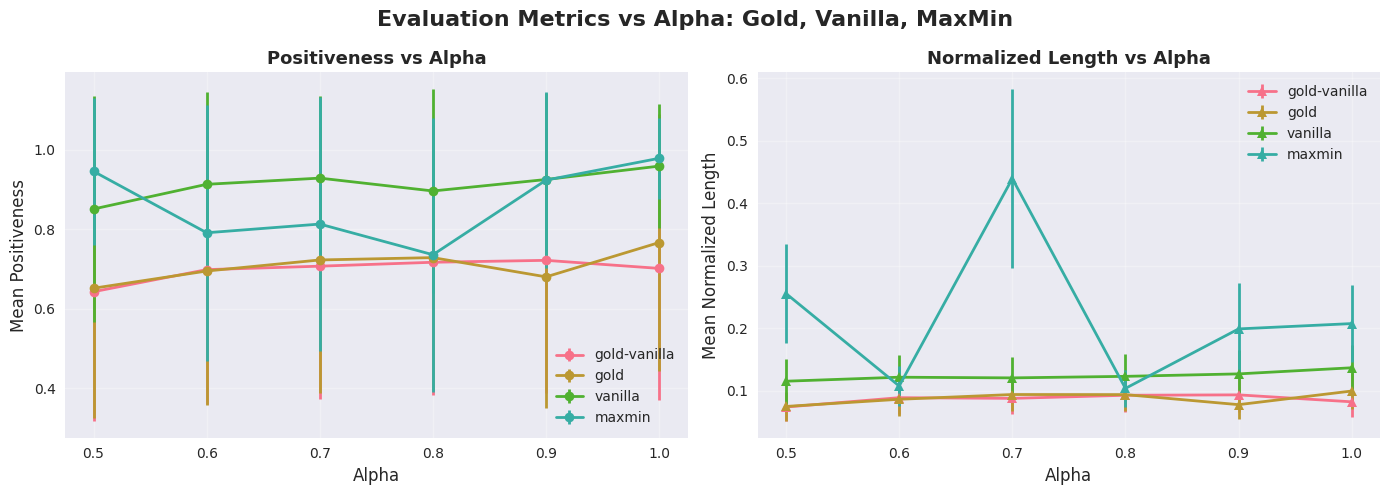

In [23]:
if 'combined_df' in locals() and len(combined_df) > 0:
    # Keep only requested metric plots by alpha.
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Evaluation Metrics vs Alpha: Gold, Vanilla, MaxMin', fontsize=16, fontweight='bold')

    # 1. Positiveness by method and alpha
    ax1 = axes[0]
    for method in METHODS:
        method_data = combined_df[combined_df['method'] == method].copy()
        method_data['positiveness'] = pd.to_numeric(method_data['positiveness'], errors='coerce')
        method_data = method_data.dropna(subset=['positiveness'])
        if len(method_data) == 0:
            continue

        alpha_means = method_data.groupby('alpha')['positiveness'].mean()
        alpha_stds = method_data.groupby('alpha')['positiveness'].std()
        ax1.errorbar(
            alpha_means.index,
            alpha_means.values,
            yerr=alpha_stds.values,
            marker='o',
            label=method,
            linewidth=2,
            markersize=7,
            capsize=4,
        )

    ax1.set_xlabel('Alpha', fontsize=12)
    ax1.set_ylabel('Mean Positiveness', fontsize=12)
    ax1.set_title('Positiveness vs Alpha', fontsize=13, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3)

    # 2. Normalized length by method and alpha
    ax2 = axes[1]
    for method in METHODS:
        method_data = combined_df[combined_df['method'] == method].copy()
        method_data['normalized_length'] = pd.to_numeric(method_data['normalized_length'], errors='coerce')
        method_data = method_data.dropna(subset=['normalized_length'])
        if len(method_data) == 0:
            continue

        alpha_means = method_data.groupby('alpha')['normalized_length'].mean()
        alpha_stds = method_data.groupby('alpha')['normalized_length'].std()
        ax2.errorbar(
            alpha_means.index,
            alpha_means.values,
            yerr=alpha_stds.values,
            marker='^',
            label=method,
            linewidth=2,
            markersize=7,
            capsize=4,
        )

    ax2.set_xlabel('Alpha', fontsize=12)
    ax2.set_ylabel('Mean Normalized Length', fontsize=12)
    ax2.set_title('Normalized Length vs Alpha', fontsize=13, fontweight='bold')
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


## Detailed Comparison: Gold, Vanilla, MaxMin


## Alpha Effect Analysis


In [24]:
if 'combined_df' in locals() and len(combined_df) > 0:
    # Analyze correlation between alpha and metrics
    print("Correlation Analysis: Alpha vs Metrics")
    print("=" * 80)
    
    for method in METHODS:
        method_data = combined_df[combined_df['method'] == method]
        
        print(f"\n{method.upper()}:")
        print("-" * 60)
        
        for metric in ['positiveness', 'length', 'normalized_length']:
            correlation = method_data['alpha'].corr(method_data[metric])
            print(f"  Alpha vs {metric}: r={correlation:.4f}")
            
            if abs(correlation) > 0.3:
                direction = "positive" if correlation > 0 else "negative"
                strength = "strong" if abs(correlation) > 0.7 else "moderate"
                print(f"    → {strength.capitalize()} {direction} correlation")


Correlation Analysis: Alpha vs Metrics

GOLD-VANILLA:
------------------------------------------------------------
  Alpha vs positiveness: r=0.0545
  Alpha vs length: r=0.1112
  Alpha vs normalized_length: r=0.1112

GOLD:
------------------------------------------------------------
  Alpha vs positiveness: r=0.0788
  Alpha vs length: r=0.1733
  Alpha vs normalized_length: r=0.1733

VANILLA:
------------------------------------------------------------
  Alpha vs positiveness: r=0.1145
  Alpha vs length: r=0.1687
  Alpha vs normalized_length: r=0.1687

MAXMIN:
------------------------------------------------------------
  Alpha vs positiveness: r=0.0849
  Alpha vs length: r=-0.1067
  Alpha vs normalized_length: r=-0.1067


## Sample Responses Comparison


In [25]:
if 'combined_df' in locals() and len(combined_df) > 0:
    # Show sample responses for comparison
    print("Sample Responses Comparison")
    print("=" * 80)
    
    # Get samples for alpha=1.0 (highest alpha)
    sample_alpha = 1.0
    
    for method in METHODS:
        method_data = combined_df[
            (combined_df['method'] == method) & 
            (combined_df['alpha'] == sample_alpha)
        ]
        
        if len(method_data) > 0:
            # Get top 3 by positiveness
            top_samples = method_data.nlargest(3, 'positiveness')
            
            print(f"\n{method.upper()} (alpha={sample_alpha}) - Top 3 by Positiveness:")
            print("-" * 60)
            
            for idx, row in top_samples.iterrows():
                pos_val = row['positiveness']
                pos_str = f"{pos_val:.4f}" if pd.notna(pos_val) else "N/A"
                print(f"\nSample {idx}:")
                print(f"  Prompt: {row['prompt'][:100]}...")
                print(f"  Completion: {row['completion'][:150]}...")
                print(f"  Positiveness: {pos_str}")
                print(f"  Length: {row['length']}")
                print(f"  Normalized Length: {row['normalized_length']:.4f}")


Sample Responses Comparison

GOLD-VANILLA (alpha=1.0) - Top 3 by Positiveness:
------------------------------------------------------------

Sample 148157:
  Prompt: This is a truly great and...
  Completion: This is a truly great and highly recommended...
  Positiveness: 0.9965
  Length: 10
  Normalized Length: 0.1000

Sample 137368:
  Prompt: This wonderful movie captures...
  Completion: This wonderful movie captures it...
  Positiveness: 0.9964
  Length: 7
  Normalized Length: 0.0700

Sample 139547:
  Prompt: This is a witty and delightful adaptation...
  Completion: This is a witty and delightful adaptation...
  Positiveness: 0.9963
  Length: 9
  Normalized Length: 0.0900

GOLD (alpha=1.0) - Top 3 by Positiveness:
------------------------------------------------------------

Sample 286226:
  Prompt: This is a magnificent,...
  Completion: This is a magnificent, perfect film....
  Positiveness: 0.9964
  Length: 10
  Normalized Length: 0.1000

Sample 291792:
  Prompt: This is an exc

## Export Results


## Group-Based Score Analysis (Majority vs Minority)


In [26]:
if 'combined_df' in locals() and len(combined_df) > 0 and 'minority_score' in combined_df.columns:
    # Group-based score analysis
    print("Group-Based Score Analysis")
    print("=" * 80)
    print(f"\nScoring formulas (applied to ALL test samples):")
    print(f"  Minority: score = (1-normalized_length)*α + (1-α)*positiveness")
    print(f"  Majority: score = (1-normalized_length)*(1-α) + α*positiveness")
    print("=" * 80)
    
    # Summary by method and alpha - compute mean minority and majority scores
    group_summary = combined_df.groupby(['method', 'alpha']).agg({
        'minority_score': ['mean', 'std', 'min', 'max'],
        'majority_score': ['mean', 'std', 'min', 'max'],
        'normalized_length': ['mean', 'std'],
        'positiveness': ['mean', 'std']
    }).round(4)
    
    print("\nGroup Score Summary by Method and Alpha:")
    print("(Mean scores computed across ALL test samples)")
    print("-" * 80)
    print(group_summary)
    
    # Flatten column names
    group_summary.columns = ['_'.join(col).strip() for col in group_summary.columns.values]
    group_summary


Group-Based Score Analysis

Scoring formulas (applied to ALL test samples):
  Minority: score = (1-normalized_length)*α + (1-α)*positiveness
  Majority: score = (1-normalized_length)*(1-α) + α*positiveness

Group Score Summary by Method and Alpha:
(Mean scores computed across ALL test samples)
--------------------------------------------------------------------------------
                   minority_score                         majority_score  \
                             mean     std     min     max           mean   
method       alpha                                                         
gold         0.5           0.7883  0.1641  0.0532  0.9824         0.7883   
             0.6           0.8261  0.1358  0.0579  0.9791         0.7824   
             0.7           0.8509  0.1019  0.1798  0.9706         0.7778   
             0.8           0.8704  0.0700  0.0440  0.9738         0.7643   
             0.9           0.8977  0.0394  0.6765  0.9725         0.7046   
             1.0

## Group Score Visualizations

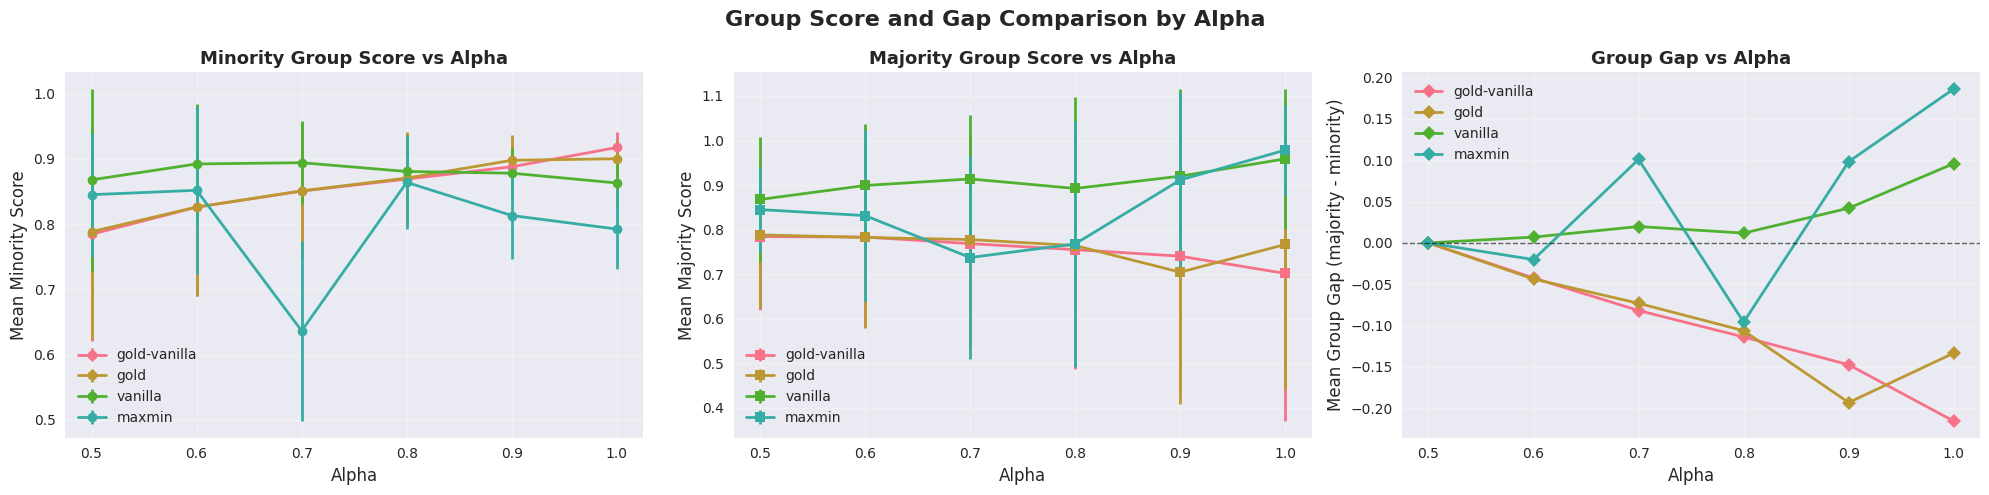

In [27]:
if 'combined_df' in locals() and len(combined_df) > 0 and 'minority_score' in combined_df.columns:
    # Score comparison in each group (minority and majority) + group gap vs alpha.
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle('Group Score and Gap Comparison by Alpha', fontsize=16, fontweight='bold')

    # 1. Minority group score comparison
    ax1 = axes[0]
    for method in METHODS:
        method_data = combined_df[combined_df['method'] == method].copy()
        method_data['minority_score'] = pd.to_numeric(method_data['minority_score'], errors='coerce')
        method_data = method_data.dropna(subset=['minority_score'])
        if len(method_data) == 0:
            continue

        alpha_means = method_data.groupby('alpha')['minority_score'].mean()
        alpha_stds = method_data.groupby('alpha')['minority_score'].std()
        ax1.errorbar(
            alpha_means.index,
            alpha_means.values,
            yerr=alpha_stds.values,
            marker='o',
            label=method,
            linewidth=2,
            markersize=7,
            capsize=4,
        )

    ax1.set_xlabel('Alpha', fontsize=12)
    ax1.set_ylabel('Mean Minority Score', fontsize=12)
    ax1.set_title('Minority Group Score vs Alpha', fontsize=13, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3)

    # 2. Majority group score comparison
    ax2 = axes[1]
    for method in METHODS:
        method_data = combined_df[combined_df['method'] == method].copy()
        method_data['majority_score'] = pd.to_numeric(method_data['majority_score'], errors='coerce')
        method_data = method_data.dropna(subset=['majority_score'])
        if len(method_data) == 0:
            continue

        alpha_means = method_data.groupby('alpha')['majority_score'].mean()
        alpha_stds = method_data.groupby('alpha')['majority_score'].std()
        ax2.errorbar(
            alpha_means.index,
            alpha_means.values,
            yerr=alpha_stds.values,
            marker='s',
            label=method,
            linewidth=2,
            markersize=7,
            capsize=4,
        )

    ax2.set_xlabel('Alpha', fontsize=12)
    ax2.set_ylabel('Mean Majority Score', fontsize=12)
    ax2.set_title('Majority Group Score vs Alpha', fontsize=13, fontweight='bold')
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)

    # 3. Group gap comparison (majority - minority) by alpha
    ax3 = axes[2]
    for method in METHODS:
        method_data = combined_df[combined_df['method'] == method].copy()
        method_data['minority_score'] = pd.to_numeric(method_data['minority_score'], errors='coerce')
        method_data['majority_score'] = pd.to_numeric(method_data['majority_score'], errors='coerce')
        method_data = method_data.dropna(subset=['minority_score', 'majority_score'])
        if len(method_data) == 0:
            continue

        gap_by_alpha = method_data.groupby('alpha').apply(
            lambda g: (g['majority_score'] - g['minority_score']).mean()
        )
        ax3.plot(
            gap_by_alpha.index,
            gap_by_alpha.values,
            marker='D',
            label=method,
            linewidth=2,
            markersize=7,
        )

    ax3.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.6)
    ax3.set_xlabel('Alpha', fontsize=12)
    ax3.set_ylabel('Mean Group Gap (majority - minority)', fontsize=12)
    ax3.set_title('Group Gap vs Alpha', fontsize=13, fontweight='bold')
    ax3.legend(fontsize=10)
    ax3.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


In [28]:
if 'combined_df' in locals() and len(combined_df) > 0:
    # Export to CSV
    output_file = f"ppo_evaluation_results_seed{SEED}.csv"
    combined_df.to_csv(output_file, index=False)
    print(f"Results exported to: {output_file}")
    
    # Export summary statistics
    if 'summary_stats' in locals():
        summary_file = f"ppo_evaluation_summary_seed{SEED}.csv"
        summary_stats.to_csv(summary_file)
        print(f"Summary statistics exported to: {summary_file}")


Results exported to: ppo_evaluation_results_seed42.csv
Summary statistics exported to: ppo_evaluation_summary_seed42.csv
